# Teslimat oranı düştü. Süreç gerçekten kötüleşti mi?

Yönetim raporunda zamanında teslim oranı %96,2’den düşüyor. Aynı dönemde depo daha fazla karmaşık sipariş aldı. Yönetici vardiya değişikliğini geri almayı düşünüyor. Önce hangi değişimin hacim karmasından, hangisinin tür içi performanstan geldiğini ayır.

Karar: Kapasiteyi karmaşık işlere mi kaydırmalıyız, süreç yöntemini mi değiştirmeliyiz?

Veriler sentetiktir. Her senaryo sabit tohumla aynı veriyi yeniden oluşturur. CSV dosyaları örnek çıktıdır. Bir CSV’yi değiştirmen bu defterin verisini otomatik değiştirmez.


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import expit
import matplotlib.pyplot as plt

BLUE, ORANGE, GREEN, GRAY = '#2457ad', '#ac452c', '#197254', '#64748b'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'axes.axisbelow': True, 'grid.alpha': .19})

def table(frame, title):
    return dict(title=title, columns=frame.columns.tolist(),
                rows=frame.astype(object).where(frame.notna(), None).values.tolist())

def kpi(scenario='default'):
    rows = [
        ['Önce', 'Standart', 900, 882, 0],
        ['Önce', 'Karmaşık', 100, 80, 0],
        ['Sonra', 'Standart', 300, 297, 0],
        ['Sonra', 'Karmaşık', 700, 588, 0],
    ]
    if scenario == 'unknown':
        rows[3][3:] = [552, 48]
    raw = pd.DataFrame(rows, columns=['Dönem', 'İş türü', 'Toplam', 'Zamanında', 'Durumu bilinmiyor'])
    raw['Gecikmiş'] = raw.Toplam - raw.Zamanında - raw['Durumu bilinmiyor']
    assert (raw.Gecikmiş >= 0).all()
    p = raw.iloc[:2]
    q = raw.iloc[2:]
    w = p.Toplam.to_numpy() / p.Toplam.sum()
    before = p.Zamanında.to_numpy() / p.Toplam.to_numpy()
    low = q.Zamanında.to_numpy() / q.Toplam.to_numpy()
    high = (q.Zamanında + q['Durumu bilinmiyor']).to_numpy() / q.Toplam.to_numpy()
    base = w @ before
    crude = [q.Zamanında.sum()/q.Toplam.sum(), (q.Zamanında.sum()+q['Durumu bilinmiyor'].sum())/q.Toplam.sum()]
    fixed = [w @ low, w @ high]
    diff = [(x-base)*100 for x in fixed]
    def display_interval(values, precision, signed=False):
        spec = ('+' if signed else '') + f'.{precision}f'
        text = [format(v, spec).replace('.',',') for v in values]
        return text[0] if np.isclose(values[0], values[1]) else ' ile '.join(text)
    crude_display = display_interval(np.array(crude)*100, 1)
    diff_display = display_interval(diff, 2, signed=True)
    info = raw[['Dönem', 'İş türü', 'Toplam', 'Zamanında', 'Durumu bilinmiyor']].copy()
    info['En düşük oran %'] = raw.Zamanında / raw.Toplam * 100
    info['En yüksek oran %'] = (raw.Zamanında+raw['Durumu bilinmiyor'])/raw.Toplam*100
    fig, ax = plt.subplots(figsize=(8.5, 4.2), layout='constrained')
    labels = ['Standart', 'Karmaşık', 'Tüm işler\nham oran', 'Tüm işler\neski dağılımla']
    old = np.r_[before, base, base]*100
    newlow = np.r_[low, crude[0], fixed[0]]*100
    newhigh = np.r_[high, crude[1], fixed[1]]*100
    x = np.arange(4)
    ax.scatter(x-.11, old, color=BLUE, label='Önce', s=65)
    ax.errorbar(x+.11, (newlow+newhigh)/2, (newhigh-newlow)/2, fmt='s', capsize=5, color=ORANGE,
                label='Sonra' if scenario=='default' else 'Sonra (bilinmeyen durum sınırları)')
    ax.set(xticks=x, xticklabels=labels, ylim=(73,101), ylabel='Zamanında teslim · %',
           title='İş karmasını sabitleyince KPI ne söylüyor?')
    ax.legend(loc='lower right', fontsize=9)
    fig2, ax2 = plt.subplots(figsize=(8.5,3.4),layout='constrained')
    ax2.barh([0,1], [90,30],color=BLUE,label='Standart')
    ax2.barh([0,1], [10,70],left=[90,30],color=ORANGE,label='Karmaşık')
    for y,a,b in [(0,90,10),(1,30,70)]:
        ax2.text(a/2,y,f'%{a}',color='white',ha='center',va='center',weight='bold')
        ax2.text(a+b/2,y,f'%{b}',color='white',ha='center',va='center',weight='bold')
    ax2.set(yticks=[0,1],yticklabels=['Önce','Sonra'],xlabel='Tüm işler içindeki pay · %',title='Sonraki dönemde karmaşık işler daha ağırlıklı')
    ax2.legend(loc='upper center',bbox_to_anchor=(.5,-.18),ncol=2)
    decision = (
        'Ham oran düşerken her iş türünde oran yükseliyor. İş karması eski ağırlıklarla sabitlendiğinde fark +1,30 yüzde puan. Hacim planı için karmaşık iş yükünü, yöntem performansı için tür bazlı oranları incele.'
        if scenario == 'default' else
        'Eski iş karmasına göre toplam farkın alt sınırı pozitif olsa da karmaşık grupta değişimin yönü bilinmiyor. Önce 48 açık teslim durumunu kapat. Sonraki dönemin ham SLA düşüşünü ve standartlaştırılmış kıyası ayrı raporla.'
    )
    return dict(metrics={'Önce · ham %':base*100,'Sonra · ham %':crude_display,
                         'Sabit karma farkı · yp':diff_display,'Bilinmeyen iş':int(raw['Durumu bilinmiyor'].sum())},
        tables=[table(info,'Aynı payda ile tür bazında KPI')], figures=[
          ('Noktalar tür bazlı oranları, dikey çizgiler bilinmeyen teslimlerin yaratabileceği sınırı gösterir. Bu çizgiler güven aralığı değildir.',fig),
          ('Önceki dönemde karmaşık işlerin payı %10, sonraki dönemde %70. Ham toplam bu değişimden etkilenir.',fig2)],
        frames={'kpi_sayimlari':raw},
        steps=['Her dönem ve iş türünde zamanında / tüm uygun iş oranını hesapla. Eksik durumları paydada tut.',
               f'Önceki karışımı referans seç: %90 standart + %10 karmaşık. Sonra sabit karma oranı %{fixed[0]*100:.2f}–%{fixed[1]*100:.2f}.',
               'Bilinmeyenlerin tamamı gecikmiş ve tamamı zamanında varsayımlarını ayrı hesapla. İki sınır arasındaki fark veri riskidir.'],
        decision=decision,limit='Dört hücre iki dönemlik sentetik sayımdır. Ağırlıklar seçilen referansa bağlıdır. Standartlaştırma yalnız gözlenen iş türünü dengeler. Dönem kıyası tek başına süreç değişikliğinin nedensel etkisini göstermez.',
        diagnostics={'crude_before':base,'crude_after':crude,'fixed':fixed,'diff_pp':diff},
        focus=[['Ham hizmet düzeyi',f'%{base*100:.1f} → %{crude[0]*100:.1f}'+(' alt sınır' if scenario=='unknown' else ''),'Müşterinin karşılaştığı toplam düzey'],
               ['Karma etkisi','%10 → %70','Karmaşık iş payı arttı'],
               ['Adil kıyas',f'{diff[0]:+.2f} yp'+(' alt sınır' if scenario=='unknown' else ''),'Eski iş dağılımı ile kıyas']])


def print_result(result):
    for name, value in result['metrics'].items():
        print(f"{name}: {value}")
    print()
    for t in result['tables']:
        print(t['title'])
        print(pd.DataFrame(t['rows'], columns=t['columns']).to_string(index=False))
        print()
    print('Karar:', result['decision'])
    print('Koşullar:', result['limit'])


## Durumlar tamam

Sonraki dönemde zamanında teslimler 297/300 standart ve 588/700 karmaşık. Eski ağırlıklar %90 ve %10. Bilinmeyenleri zamanında saymadan, sabit karma oranı önceki %96,2’ye göre kaç yüzde puan değişti?


Önce · ham %: 96.2
Sonra · ham %: 88,5
Sabit karma farkı · yp: +1,30
Bilinmeyen iş: 0

Aynı payda ile tür bazında KPI
Dönem  İş türü  Toplam  Zamanında  Durumu bilinmiyor  En düşük oran %  En yüksek oran %
 Önce Standart     900        882                  0             98.0              98.0
 Önce Karmaşık     100         80                  0             80.0              80.0
Sonra Standart     300        297                  0             99.0              99.0
Sonra Karmaşık     700        588                  0             84.0              84.0

Karar: Ham oran düşerken her iş türünde oran yükseliyor. İş karması eski ağırlıklarla sabitlendiğinde fark +1,30 yüzde puan. Hacim planı için karmaşık iş yükünü, yöntem performansı için tür bazlı oranları incele.
Koşullar: Dört hücre iki dönemlik sentetik sayımdır. Ağırlıklar seçilen referansa bağlıdır. Standartlaştırma yalnız gözlenen iş türünü dengeler. Dönem kıyası tek başına süreç değişikliğinin nedensel etkisini göstermez.


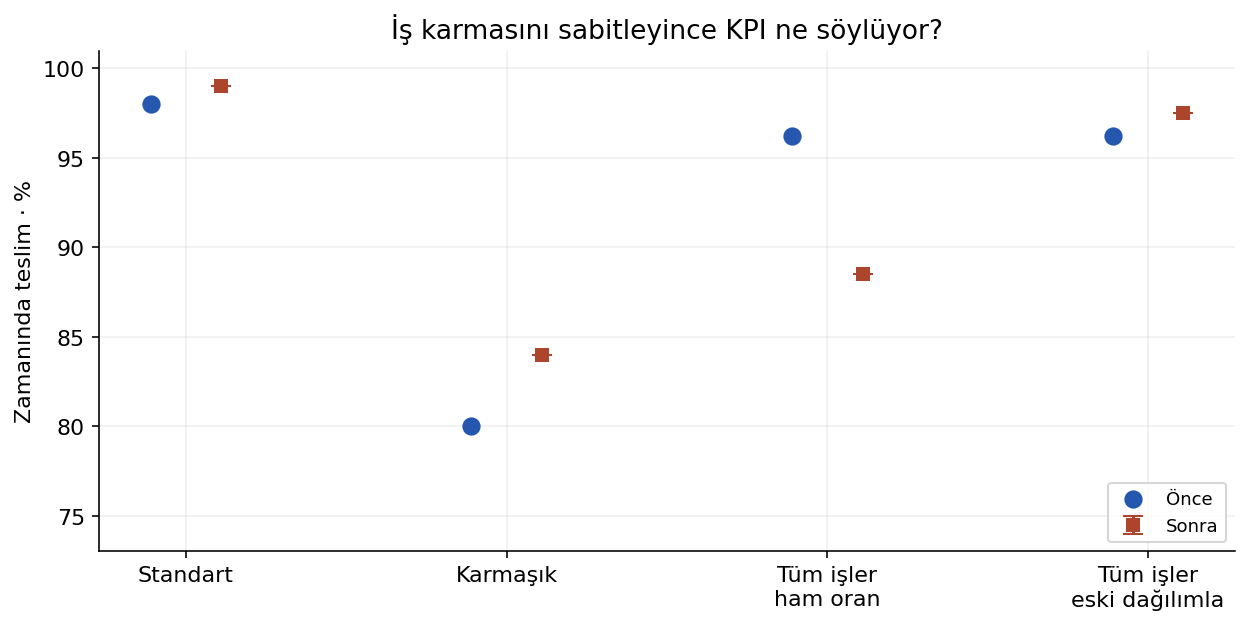

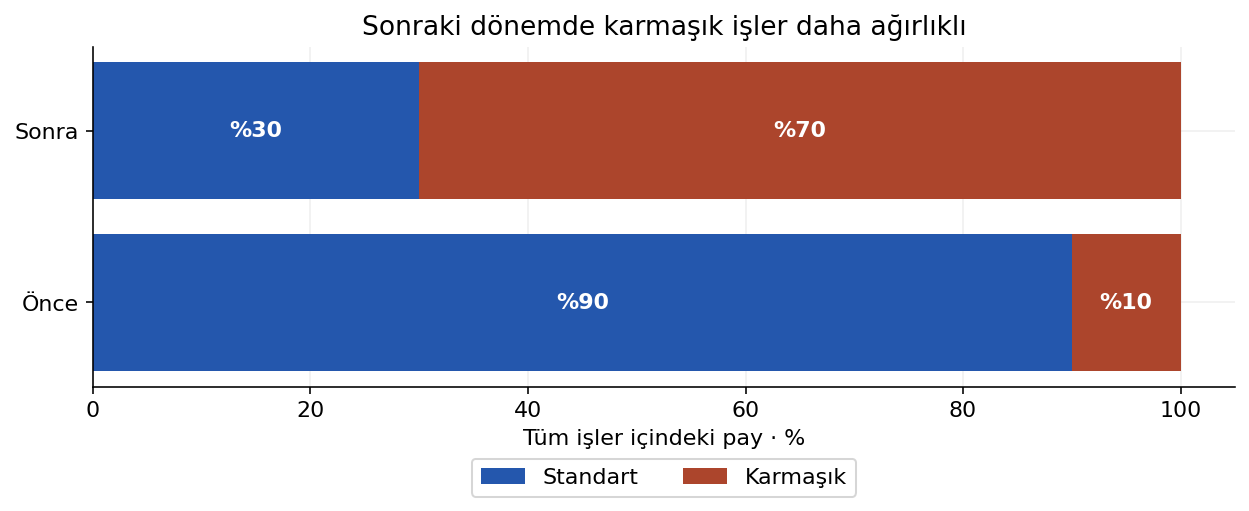

In [2]:
result = kpi('default')
print_result(result)
plt.show()


## 48 karmaşık işin durumu belirsiz

Sonraki dönemde zamanında teslimler 297/300 standart ve 552/700 karmaşık. Eski ağırlıklar %90 ve %10. Bilinmeyenleri zamanında saymadan, sabit karma oranı önceki %96,2’ye göre kaç yüzde puan değişti?


Önce · ham %: 96.2
Sonra · ham %: 84,9 ile 89,7
Sabit karma farkı · yp: +0,79 ile +1,47
Bilinmeyen iş: 48

Aynı payda ile tür bazında KPI
Dönem  İş türü  Toplam  Zamanında  Durumu bilinmiyor  En düşük oran %  En yüksek oran %
 Önce Standart     900        882                  0        98.000000         98.000000
 Önce Karmaşık     100         80                  0        80.000000         80.000000
Sonra Standart     300        297                  0        99.000000         99.000000
Sonra Karmaşık     700        552                 48        78.857143         85.714286

Karar: Eski iş karmasına göre toplam farkın alt sınırı pozitif olsa da karmaşık grupta değişimin yönü bilinmiyor. Önce 48 açık teslim durumunu kapat. Sonraki dönemin ham SLA düşüşünü ve standartlaştırılmış kıyası ayrı raporla.
Koşullar: Dört hücre iki dönemlik sentetik sayımdır. Ağırlıklar seçilen referansa bağlıdır. Standartlaştırma yalnız gözlenen iş türünü dengeler. Dönem kıyası tek başına süreç değişikliğinin nede

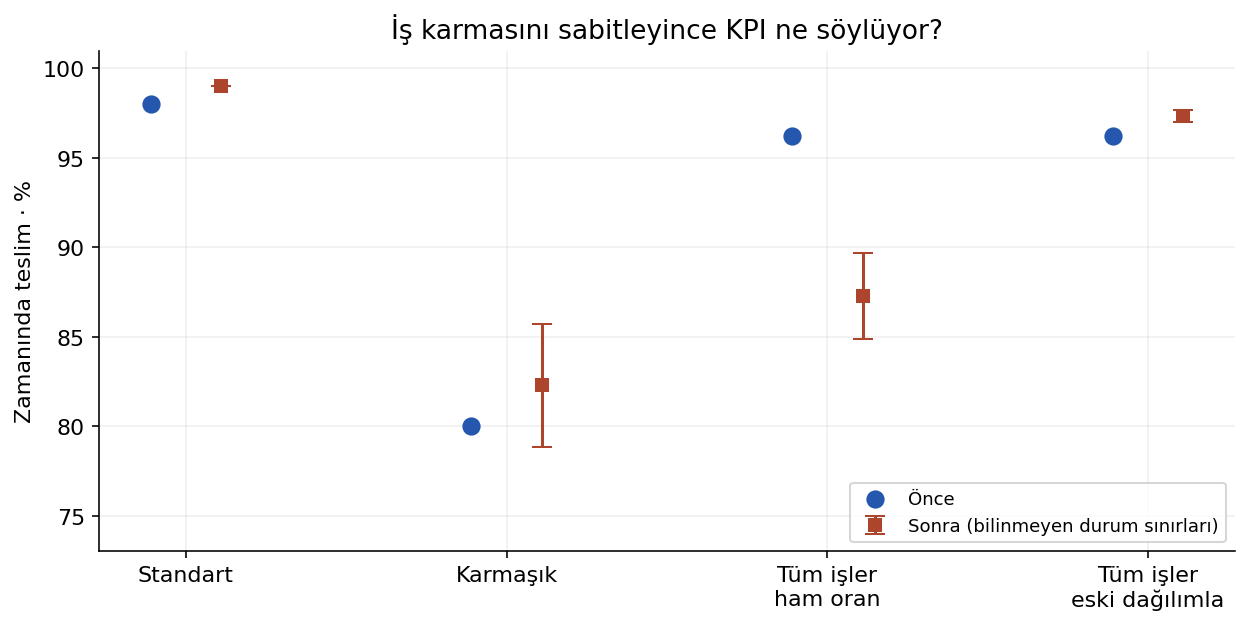

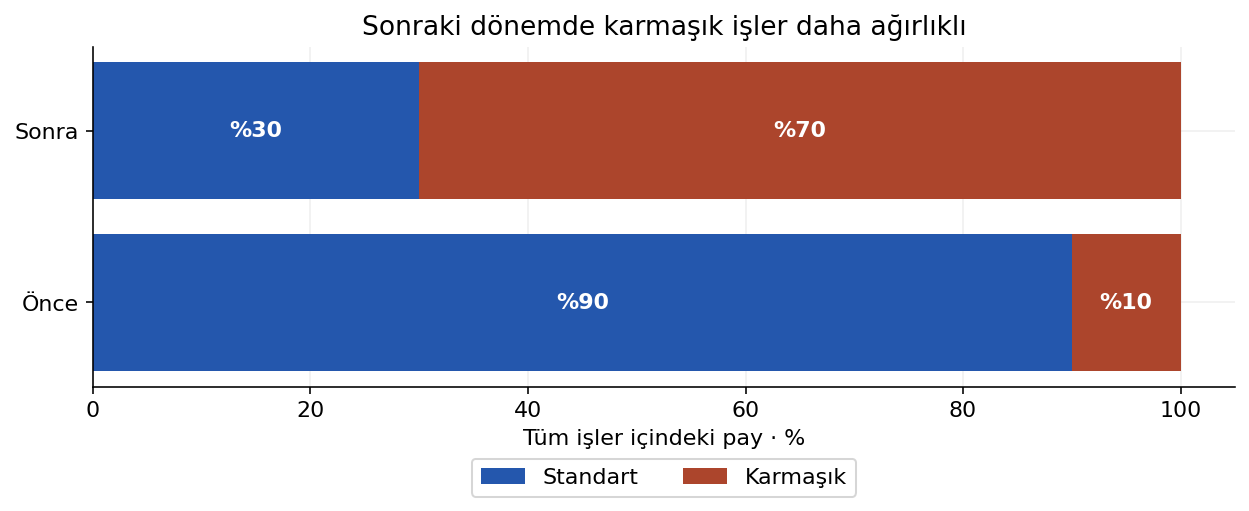

In [3]:
result = kpi('unknown')
print_result(result)
plt.show()


## Karar notu

İki senaryoda da yöneticine üç cümle yaz. Bir cümle ham hizmet düzeyini, bir cümle aynı karma kıyasını, bir cümle veriye ilişkin sonraki adımı anlatsın.

- Aynı iş türündeki pay ve paydayı doğru tanımla.
- Ham oran ile aynı karma oranının farklı sorulara yanıt verdiğini açıkla.
- Bilinmeyen durum senaryosunda karmaşık iş için kesin yön iddia etme.